# 07 · Bloomberg extras: professional news vs. Reddit, and a second gold price

Two side checks using the Bloomberg pull. Neither is a new model of Reddit; both describe or stress-test.

1. **Do Reddit and professional news move together?** Daily Reddit mood (VADER, unvalidated) against
   Bloomberg's own news sentiment for five gold miners (NEM, AEM, KGC, WPM, FNV; Bloomberg has **no**
   sentiment field for gold itself, pitfall #37), and against "real money" GLD+IAU ETF flows. Also weekly
   Reddit post counts against Bloomberg's weekly count of gold news stories (2024+). Correlations only,
   so nothing is learned from the data.
2. **Does the hourly result depend on the price source?** `04_model.ipynb` used Yahoo's GC=F futures.
   Here the same four models run on Bloomberg **spot** gold (XAU), with the same split.

In [1]:
import os
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

FIGURES = Path("reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
WINDOW = ("2026-09-08", "2026-10-05T16:00")  # frozen collection window (handoff §2)

from scipy.stats import spearmanr
daily = pd.read_parquet("data/bbg/daily_features.parquet")

## 1. Reddit mood vs. Bloomberg miner news mood, daily 2022–2026

Reddit mood vs. miner news, same day, daily values: Spearman rho = +0.06 (p = 0.0377, n = 1211)
Reddit mood vs. miner news, 20-day means: Spearman rho = +0.37 (p = 2.22e-41, n = 1218)
(20-day means overlap from day to day, so their p-value overstates certainty; read the rho only.)


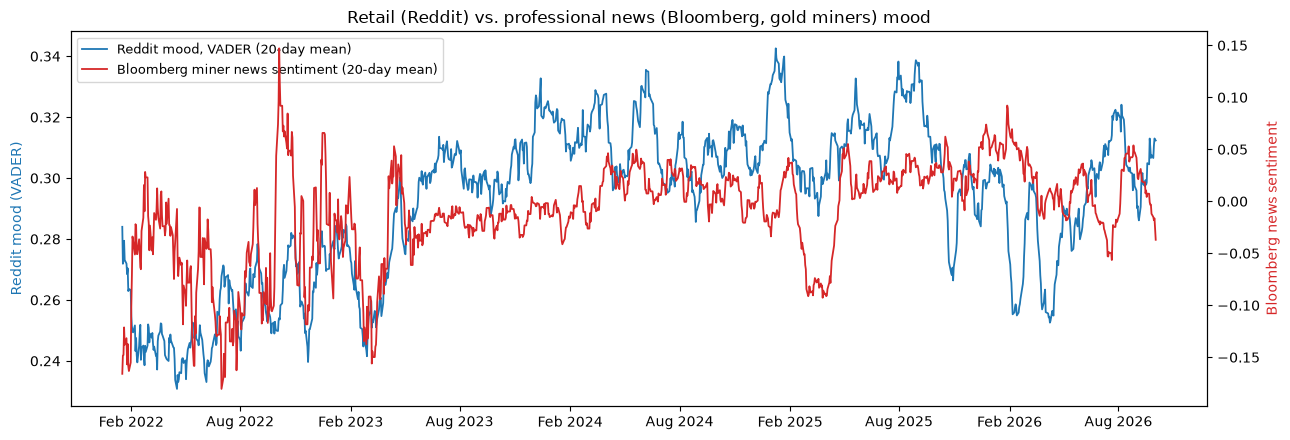

In [2]:
import matplotlib.dates as mdates
news = daily["miner_news"]
reddit = daily["mean_sentiment"].where(daily["had_posts"])
fig, ax1 = plt.subplots(figsize=(13, 4.5))
ax1.plot(daily.index, reddit.rolling(20, min_periods=10).mean(), color="tab:blue", lw=1.3, label="Reddit mood, VADER (20-day mean)")
ax1.set_ylabel("Reddit mood (VADER)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(daily.index, news.rolling(20, min_periods=10).mean(), color="tab:red", lw=1.3, label="Bloomberg miner news sentiment (20-day mean)")
ax2.set_ylabel("Bloomberg news sentiment", color="tab:red")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left", fontsize=9)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.set_title("Retail (Reddit) vs. professional news (Bloomberg, gold miners) mood")
fig.tight_layout()
fig.savefig(FIGURES / "extra_1_reddit_vs_bloomberg_news.png", dpi=150, bbox_inches="tight")

def spear(a, b):
    both = pd.concat([a, b], axis=1).dropna()
    r, p = spearmanr(both.iloc[:, 0], both.iloc[:, 1])
    return r, p, len(both)
for label, a, b in [("same day, daily values", reddit, news),
                    ("20-day means", reddit.rolling(20, min_periods=10).mean(), news.rolling(20, min_periods=10).mean())]:
    r, p, n = spear(a, b)
    print(f"Reddit mood vs. miner news, {label}: Spearman rho = {r:+.2f} (p = {p:.3g}, n = {n})")
print("(20-day means overlap from day to day, so their p-value overstates certainty; read the rho only.)")

**Lead / lag.** Positive *k* = the second series *k* trading days **later** than Reddit. If Reddit led
professional news or ETF money, the correlation would peak at positive *k*.

In [3]:
flow = daily["etf_flow_pct"]
posts = daily["log_posts_per_day"]
rows = []
for k in range(-5, 6):
    r1, p1, _ = spear(reddit, news.shift(-k))
    r2, p2, _ = spear(reddit, flow.shift(-k))
    r3, p3, _ = spear(posts, flow.shift(-k))
    rows.append({"k (days)": k, "mood vs news": r1, "p (news)": p1, "mood vs ETF flow": r2, "p (flow)": p2,
                 "chatter vs ETF flow": r3, "p (chatter)": p3})
leadlag = pd.DataFrame(rows).set_index("k (days)")
print("11 lags x 3 pairs = 33 tests; by Bonferroni only p < 0.0015 counts as more than chance.")
leadlag.round(3)

11 lags x 3 pairs = 33 tests; by Bonferroni only p < 0.0015 counts as more than chance.


,mood vs news,p (news),mood vs ETF flow,p (flow),chatter vs ETF flow,p (chatter)
k (days),,,,,,
-5,0.013,0.656,0.007,0.818,0.133,0.0
-4,0.034,0.234,0.033,0.249,0.130,0.0
-3,0.057,0.049,0.011,0.696,0.133,0.0
-2,0.022,0.437,0.008,0.787,0.137,0.0
-1,0.030,0.295,0.011,0.713,0.140,0.0
0,0.060,0.038,0.070,0.016,0.133,0.0
1,0.042,0.142,0.012,0.678,0.136,0.0
2,0.080,0.005,0.063,0.031,0.125,0.0
3,0.034,0.232,0.035,0.223,0.134,0.0


## 2. Weekly attention: Reddit posts vs. Bloomberg gold news stories (2024+)

144 weeks, 2024-01-05 -> 2026-10-02 (weeks ending Friday)
Reddit posts vs. Bloomberg gold stories, weekly levels: Spearman rho = -0.44 (p = 3.51e-08, n = 144)
Reddit posts vs. Bloomberg gold stories, week-on-week changes: Spearman rho = +0.10 (p = 0.241, n = 143)


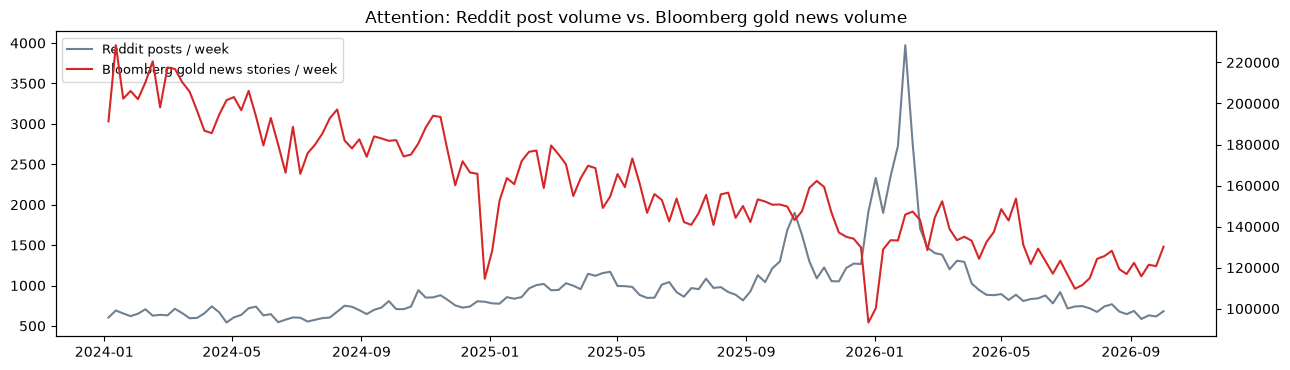

In [4]:
weekly_news = pd.read_parquet("data/bbg/gold_news_weekly.parquet").set_index("week")["story_count"]
weekly_news = weekly_news.iloc[:-1]   # the last week was pulled mid-week (partial)
hist = pd.read_parquet("data/clean/history_posts.parquet")
hist["created_utc"] = pd.to_datetime(hist["created_utc"], utc=True, format="ISO8601")
weekly_reddit = hist.set_index("created_utc").tz_convert(None).resample("W-FRI").size()
both = pd.DataFrame({"reddit_posts": weekly_reddit, "gold_news_stories": weekly_news}).dropna()
print(f"{len(both)} weeks, {both.index.min():%Y-%m-%d} -> {both.index.max():%Y-%m-%d} (weeks ending Friday)")
for label, d in [("weekly levels", both), ("week-on-week changes", both.diff().dropna())]:
    r, p = spearmanr(d["reddit_posts"], d["gold_news_stories"])
    print(f"Reddit posts vs. Bloomberg gold stories, {label}: Spearman rho = {r:+.2f} (p = {p:.3g}, n = {len(d)})")
fig, ax1 = plt.subplots(figsize=(13, 3.8))
ax1.plot(both.index, both["reddit_posts"], color="slategray", label="Reddit posts / week")
ax2 = ax1.twinx()
ax2.plot(both.index, both["gold_news_stories"], color="tab:red", label="Bloomberg gold news stories / week")
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper left", fontsize=9)
ax1.set_title("Attention: Reddit post volume vs. Bloomberg gold news volume")
fig.tight_layout()
fig.savefig(FIGURES / "extra_2_weekly_attention.png", dpi=150, bbox_inches="tight")

## 3. Hourly models on Bloomberg spot gold instead of GC=F futures
`data/bbg/features_bbg.parquet` is built exactly like `features.parquet`, except prices come from Bloomberg
spot (`python -m processing.bucket --price-file data/bbg/xau_spot_hourly.parquet ...`). Spot trades in hours
when COMEX futures are shut, so there are more valid hours. Same split: train before Sept 28, test after.

In [5]:
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from processing.features import PRICE_FEATURES, SENTIMENT_FEATURES

ALL = PRICE_FEATURES + SENTIMENT_FEATURES
SPLIT = pd.Timestamp("2026-09-28 00:00", tz="UTC")
M = ["1 majority class", "2 logistic, price-only", "3 logistic, price + sentiment",
     "4 decision tree (depth 3), price + sentiment"]

def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

def run_models(features):
    # Spot trades in the grid's first two hours, before the 1-2h lags exist: drop those warm-up rows.
    data = features[features["target_valid"]].dropna(subset=ALL).copy()
    data["y"] = data["price_direction"].astype(int)
    train, test = data[data.index < SPLIT], data[data.index >= SPLIT]
    models = {M[0]: (DummyClassifier(strategy="most_frequent"), []),
              M[1]: (make_pipeline(StandardScaler(), LogisticRegression()), PRICE_FEATURES),
              M[2]: (make_pipeline(StandardScaler(), LogisticRegression()), ALL),
              M[3]: (DecisionTreeClassifier(max_depth=3, random_state=0), ALL)}
    preds, rows = {}, []
    for name, (model, cols) in models.items():
        X_tr = train[cols] if cols else np.zeros((len(train), 1))
        X_te = test[cols] if cols else np.zeros((len(test), 1))
        model.fit(X_tr, train["y"])
        preds[name] = model.predict(X_te)
        k = int((preds[name] == test["y"]).sum())
        lo, hi = wilson(k, len(test))
        rows.append({"model": name, "n_features": len(cols), "n_train": len(train), "n_test": len(test),
                     "train_acc": (model.predict(X_tr) == train["y"]).mean(), "test_acc": k / len(test),
                     "ci95_low": lo, "ci95_high": hi, "pred_up_share": preds[name].mean()})
    return pd.DataFrame(rows), preds, test["y"].to_numpy()

gcf, _, _ = run_models(pd.read_parquet("data/clean/features.parquet"))
prior = pd.read_csv("reports/model_results.csv")
prior = prior[prior["dataset"] == "VADER, all communities"].set_index("model")["test_acc"]
for name in M:   # the GC=F side must reproduce 04_model exactly
    assert round(gcf.set_index("model").loc[name, "test_acc"], 4) == round(prior[name], 4), name

spot, preds, y = run_models(pd.read_parquet("data/bbg/features_bbg.parquet"))
print(f"Test hours: GC=F {gcf['n_test'].iloc[0]}, Bloomberg spot {spot['n_test'].iloc[0]}")
for m in M[2:]:
    a, b = preds[M[1]], preds[m]
    oa, ob = int(((a == y) & (b != y)).sum()), int(((b == y) & (a != y)).sum())
    print(f"{m:<46} vs price-only on spot: McNemar p = {binomtest(ob, oa + ob, 0.5).pvalue if oa + ob else 1.0:.3f}")
pd.DataFrame({"GC=F futures (04_model)": gcf.set_index("model")["test_acc"],
              "Bloomberg spot": spot.set_index("model")["test_acc"]}).map("{:.1%}".format)

Test hours: GC=F 124, Bloomberg spot 129
3 logistic, price + sentiment                  vs price-only on spot: McNemar p = 0.203
4 decision tree (depth 3), price + sentiment   vs price-only on spot: McNemar p = 0.155


,GC=F futures (04_model),Bloomberg spot
model,,
1 majority class,49.2%,47.3%
"2 logistic, price-only",48.4%,46.5%
"3 logistic, price + sentiment",56.5%,54.3%
"4 decision tree (depth 3), price + sentiment",51.6%,55.8%


In [6]:
out = pd.read_csv("reports/model_results.csv")
DATASET = "hourly, Bloomberg spot"
out = pd.concat([out[out["dataset"] != DATASET], spot.assign(dataset=DATASET)[out.columns]], ignore_index=True)
out.round(4).to_csv("reports/model_results.csv", index=False)